In [1]:

# Cell 1: Imports and reproducibility

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler




In [2]:
tf.keras.utils.set_random_seed(42)

# Cell 2: Create classification dataset

X, y = make_moons(
    n_samples=2000,
    noise=0.25,
    random_state=42
)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Fit the scaler ONLY on training features
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train).astype("float32")
X_test = scaler.transform(X_test).astype("float32")

y_train = y_train.astype("float32")
y_test = y_test.astype("float32")

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)



Training data: (1600, 2)
Testing data: (400, 2)


In [3]:
# Cell 3: Define RMSNorm
# RMSNorm scales by root-mean-square.
# Unlike LayerNorm, it does not subtract the mean.

class RMSNorm(tf.keras.layers.Layer):
    def __init__(self, epsilon=1e-6, **kwargs):
        super().__init__(**kwargs)
        self.epsilon = epsilon

    def build(self, input_shape):
        self.scale = self.add_weight(
            name="scale",
            shape=(input_shape[-1],),
            initializer="ones",
            trainable=True
        )

    def call(self, inputs):
        mean_square = tf.reduce_mean(
            tf.square(inputs),
            axis=-1,
            keepdims=True
        )

        inverse_rms = tf.math.rsqrt(
            mean_square + self.epsilon
        )

        return inputs * inverse_rms * self.scale

# Cell 4: Create comparable models

def build_model(norm_type):
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(2,)),
        tf.keras.layers.Dense(64, use_bias=(norm_type != "batch")),
    ])

    if norm_type == "batch":
        model.add(tf.keras.layers.BatchNormalization())
    elif norm_type == "layer":
        model.add(tf.keras.layers.LayerNormalization())
    elif norm_type == "rms":
        model.add(RMSNorm())
    elif norm_type == "none":
        pass

    model.add(tf.keras.layers.Activation("relu"))
    model.add(tf.keras.layers.Dense(32, activation="relu"))
    model.add(tf.keras.layers.Dense(1, activation="sigmoid"))

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    return model

# Cell 5: Train each model

histories = {}
results = {}

for norm_type in ["none", "batch", "layer", "rms"]:
    print(f"\nTraining model: {norm_type}")

    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(42)

    model = build_model(norm_type)

    history = model.fit(
        X_train,
        y_train,
        validation_split=0.2,
        epochs=40,
        batch_size=32,
        verbose=0
    )

    test_loss, test_accuracy = model.evaluate(
        X_test,
        y_test,
        verbose=0
    )

    histories[norm_type] = history.history
    results[norm_type] = {
        "test_loss": test_loss,
        "test_accuracy": test_accuracy
    }

    print("Test loss:", round(test_loss, 4))
    print("Test accuracy:", round(test_accuracy, 4))

# Cell 6: Compare test results

results_df = __import__("pandas").DataFrame(results).T
display(results_df)




Training model: none
Test loss: 0.1687
Test accuracy: 0.925

Training model: batch
Test loss: 0.1727
Test accuracy: 0.9275

Training model: layer
Test loss: 0.1791
Test accuracy: 0.9225

Training model: rms
Test loss: 0.1784
Test accuracy: 0.9225


,test_loss,test_accuracy
none,0.168703,0.9250
batch,0.172707,0.9275
layer,0.179089,0.9225
rms,0.178414,0.9225


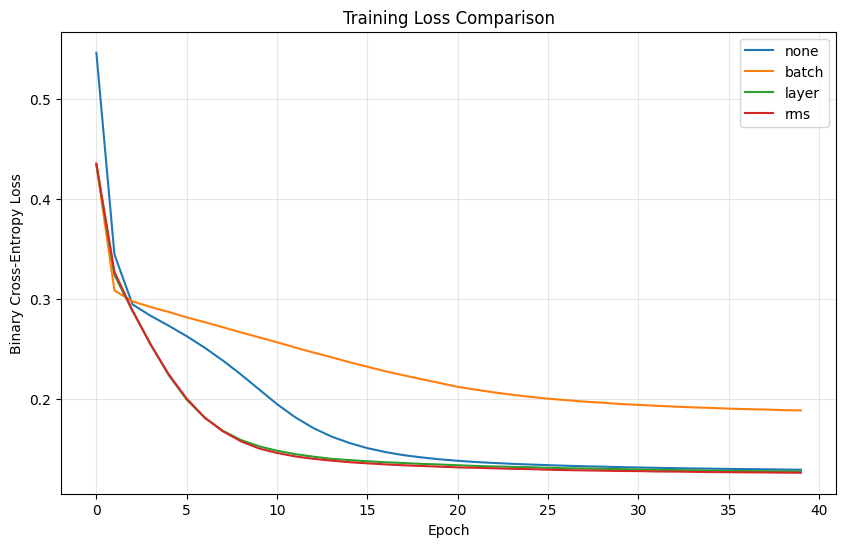

In [4]:
# Cell 7: Compare training loss

plt.figure(figsize=(10, 6))

for name, history in histories.items():
    plt.plot(history["loss"], label=name)

plt.title("Training Loss Comparison")
plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.show()



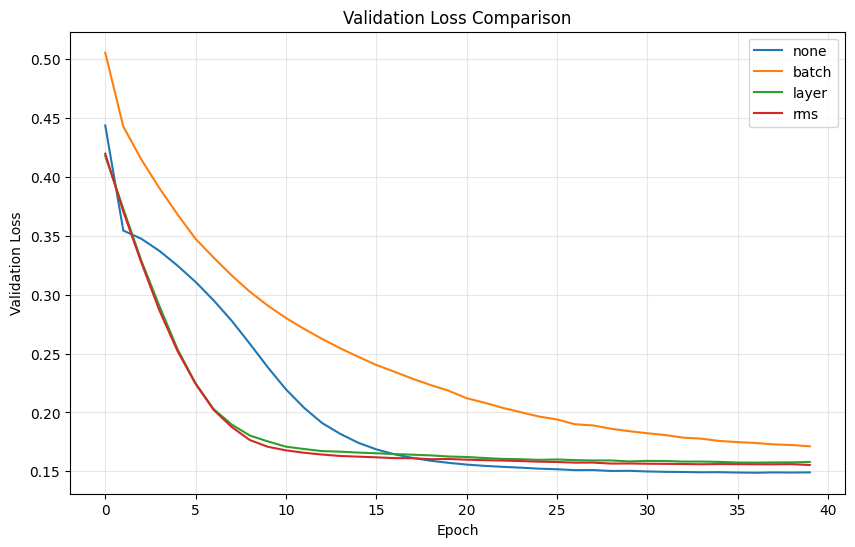

In [5]:
# Cell 8: Compare validation loss

plt.figure(figsize=(10, 6))

for name, history in histories.items():
    plt.plot(history["val_loss"], label=name)

plt.title("Validation Loss Comparison")
plt.xlabel("Epoch")
plt.ylabel("Validation Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.show()